In [10]:
!pip install cairosvg -q

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import cairosvg
from google.colab import files

In [3]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- box.png")
print("- box_in_scene.png")
print("- Azerbaijan-Emblem")
print("- Azerbaijan-Passport")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded: {filename}")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- box.png
- box_in_scene.png
- Azerbaijan-Emblem
- Azerbaijan-Passport


Saving Azerbaijan-Emblem.svg to Azerbaijan-Emblem.svg
Saving Azerbaijan-Passport.svg to Azerbaijan-Passport.svg
Saving box.png to box.png
Saving box_in_scene.png to box_in_scene.png
Uploaded: Azerbaijan-Emblem.svg
Uploaded: Azerbaijan-Passport.svg
Uploaded: box.png
Uploaded: box_in_scene.png

Contents Of Images Folder:
['box_in_scene.png', 'Azerbaijan-Emblem.svg', 'Azerbaijan-Passport.svg', 'box.png']


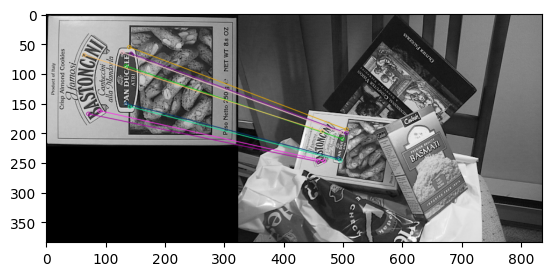

In [6]:
img1 = cv2.imread('images/box.png')
img2 = cv2.imread('images/box_in_scene.png', 0)

orb = cv2.ORB_create()

kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x:x.distance)

img3 = cv2.drawMatches(img1, kp1, img2, kp2, matches[:10], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.imshow(img3)

plt.show()

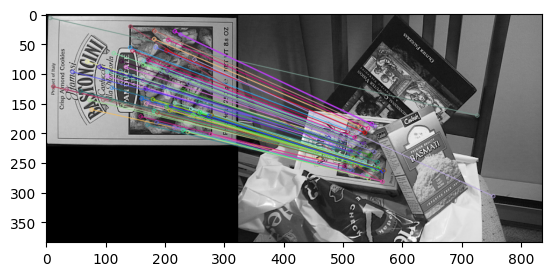

In [7]:
img1 = cv2.imread('images/box.png', 0)
img2 = cv2.imread('images/box_in_scene.png', 0)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher()

matches = bf.knnMatch(des1, des2, k=2)

good = []
for m,n in matches:
  if m.distance < 0.75 * n.distance:
    good.append([m])

img3 = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.imshow(img3)

plt.show()

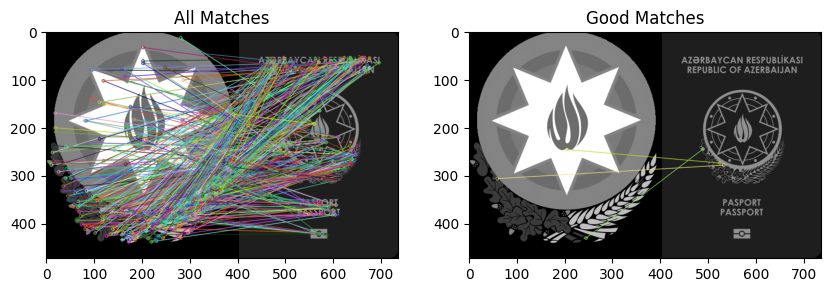

In [12]:
cairosvg.svg2png(url='images/Azerbaijan-Emblem.svg', write_to='images/Azerbaijan-Emblem.png')
cairosvg.svg2png(url='images/Azerbaijan-Passport.svg', write_to='images/Azerbaijan-Passport.png')

img1 = cv2.imread('images/Azerbaijan-Emblem.png', 0)
img2 = cv2.imread('images/Azerbaijan-Passport.png', 0)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher()
matches = bf.match(des1, des2)

img3 = cv2.drawMatches(img1, kp1, img2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

matches = bf.knnMatch(des1, des2, k=2)

good = []
for m,n in matches:
  if m.distance < 0.75 * n.distance:
    good.append([m])

img4 = cv2.drawMatchesKnn(img1, kp1, img2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img3, cmap='gray')
plt.title('All Matches')

plt.subplot(1, 2, 2)
plt.imshow(img4, cmap='gray')
plt.title('Good Matches')

plt.show()

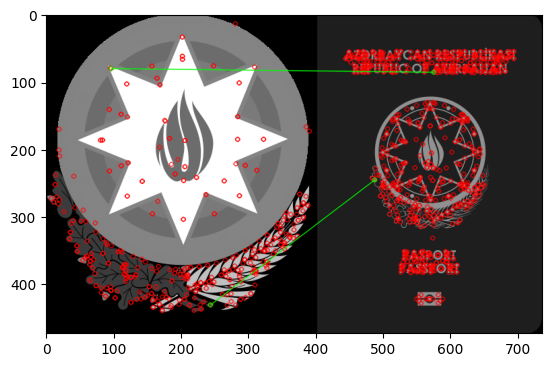

In [14]:
cairosvg.svg2png(url='images/Azerbaijan-Emblem.svg', write_to='images/Azerbaijan-Emblem.png')
cairosvg.svg2png(url='images/Azerbaijan-Passport.svg', write_to='images/Azerbaijan-Passport.png')

img1 = cv2.imread('images/Azerbaijan-Emblem.png', 0)
img2 = cv2.imread('images/Azerbaijan-Passport.png', 0)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

FLAN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLAN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

matchesMask = [[0, 0] for i in range(len(matches))]

for i, (m, n) in enumerate(matches):
  if m.distance < 0.7 * n.distance:
    matchesMask[i] = [1, 0]

draw_params = dict(matchColor=(0, 255, 0),
                   singlePointColor=(255, 0, 0),
                   matchesMask=matchesMask,
                   flags=cv2.DrawMatchesFlags_DEFAULT)

img3 = cv2.drawMatchesKnn(img1, kp1, img2, kp2, matches, None, **draw_params)

plt.imshow(img3)

plt.show()